# Amazon Reviews 2023 - Beauty Category - Sentiment Analysis

This notebook builds a clean, unbiased, and reproducible pipeline for a
sentiment analysis project on the **All Beauty** subset of the
Amazon Reviews 2023 dataset (https://amazon-reviews-2023.github.io/).

**Pipeline overview:**
1. Install & import libraries
2. Load reviews + metadata
3. Merge datasets and create the sentiment target
4. Clean the merged dataframe (drop leakage/unneeded columns, duplicates, nulls)
5. Draw a stratified (unbiased) sample from the full dataset
6. Split into train / validation / test (stratified)
7. Exploratory Data Analysis (EDA)
8. Text preprocessing - two separate pipelines:
   - Classical ML pipeline (TF-IDF based models)
   - Transformer pipeline (DistilBERT / BERT / RoBERTa)
9. Preparing data for a transformer model (tokenization)


## 1. Install & import required libraries

In [ ]:
# Install the datasets library (only needed once per environment)
!pip install datasets==2.20.0 -q
!pip install scikit-learn nltk wordcloud matplotlib seaborn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.1/316.1 kB 33.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.5.0 which is incompatible.


In [ ]:
# Core libraries
import re
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ML
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Download NLTK resources (only needed once)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Load the reviews dataset (All Beauty)

In [ ]:
from datasets import load_dataset

# Load raw reviews for the "All Beauty" category
dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_review_All_Beauty",
    trust_remote_code=True
)

# Quick look at a single example
print(dataset["full"][0])


Generating full split: 0 examples [00:00, ? examples/s]

{'rating': 5.0, 'title': 'Such a lovely scent but not overpowering.', 'text': "This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comparing to other brands with yucky chemicals so I'm gonna stick with this. Try it!", 'images': [], 'asin': 'B00YQ6X8EO', 'parent_asin': 'B00YQ6X8EO', 'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'timestamp': 1588687728923, 'helpful_vote': 0, 'verified_purchase': True}


In [ ]:
df = pd.DataFrame(dataset["full"])
print("Reviews shape:", df.shape)
df.head(3)


Reviews shape: (701528, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True


## 3. Load the metadata dataset (product info) and merge

In [ ]:
dataset_meta = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_meta_All_Beauty",
    trust_remote_code=True
)
df_meta = pd.DataFrame(dataset_meta["full"])
print("Metadata shape (before dedup):", df_meta.shape)


Generating full split:   0%|          | 0/112590 [00:00<?, ? examples/s]

Metadata shape (before dedup): (112590, 16)


In [ ]:
# FIX #1: the metadata table can have multiple rows for the same parent_asin.
# If we merge without deduplicating first, review rows get duplicated during the
# left join, which silently inflates the dataset and biases any downstream sample.
n_dup_products = df_meta["parent_asin"].duplicated().sum()
print("Duplicated parent_asin rows in metadata:", n_dup_products)

df_meta = df_meta.drop_duplicates(subset="parent_asin", keep="first")
print("Metadata shape (after dedup):", df_meta.shape)


Duplicated parent_asin rows in metadata: 0
Metadata shape (after dedup): (112590, 16)


In [ ]:
# Merge reviews with product metadata on parent_asin
merged_df = pd.merge(df, df_meta, on="parent_asin", how="left")
print("Merged shape:", merged_df.shape)

# Sanity check: merged row count should equal the original reviews row count
# now that metadata duplicates were removed.
assert merged_df.shape[0] == df.shape[0], "Merge produced extra rows - check for duplicate keys."


Merged shape: (701528, 25)


In [ ]:
# Create the sentiment target directly from the numeric rating
sentiment_mapping = {
    1.0: "Very Negative",
    2.0: "Negative",
    3.0: "Neutral",
    4.0: "Positive",
    5.0: "Very Positive"
}
merged_df["sentiment"] = merged_df["rating"].map(sentiment_mapping)
merged_df["sentiment"].value_counts()


,count
sentiment,
Very Positive,420726
Very Negative,102080
Positive,79381
Neutral,56307
Negative,43034


## 4. Cleaning the merged dataframe



In [ ]:
# Merge review title and review text into a single text column
merged_df["review"] = (
    merged_df["title_x"].fillna("").astype(str)
    + " "
    + merged_df["text"].fillna("").astype(str)
)


In [ ]:
# Drop columns that are not useful for sentiment analysis
columns_to_drop = [
    "images_x",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "images_y",
    "videos",
    "categories",
    "bought_together",
    "subtitle",
    "author",
    "title_x",
    "text",
]
merged_df.drop(columns=columns_to_drop, inplace=True)
print(merged_df.columns.tolist())


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'price', 'store', 'details', 'sentiment', 'review']


In [ ]:
# Drop rows with an empty review after merging title + text
before = merged_df.shape[0]
merged_df = merged_df[
    merged_df["review"].notna() & (merged_df["review"].str.strip() != "")
].copy()
print(f"Dropped {before - merged_df.shape[0]} rows with empty reviews.")


Dropped 0 rows with empty reviews.


In [ ]:
# Remove duplicate reviews (exact text duplicates, e.g. copy-pasted or spam reviews)
before = merged_df.shape[0]
merged_df.drop_duplicates(subset=["review"], inplace=True)
print(f"Dropped {before - merged_df.shape[0]} duplicate reviews.")


Dropped 29904 duplicate reviews.


In [ ]:
# Remove reviews that are too short to carry sentiment information (< 3 words)
before = merged_df.shape[0]
merged_df = merged_df[merged_df["review"].str.split().str.len() >= 3].copy()
print(f"Dropped {before - merged_df.shape[0]} reviews shorter than 3 words.")


Dropped 2776 reviews shorter than 3 words.


In [ ]:
# Check remaining missing values
merged_df.isnull().sum().sort_values(ascending=False)


,0
store,46889
rating,0
verified_purchase,0
main_category,0
title_y,0
helpful_vote,0
average_rating,0
rating_number,0
description,0
features,0


In [ ]:
# 'store' has too many missing values and is not useful for sentiment analysis
merged_df.drop(columns=["store"], inplace=True)


In [ ]:
# FIX #3: price was stored as an object (mixed types like the string "None").
# Convert to numeric and inspect how many values are missing.
merged_df["price"] = pd.to_numeric(merged_df["price"], errors="coerce")
print("Missing price values:", merged_df["price"].isnull().sum())

# price is not relevant to sentiment and has too many missing values -> drop it
merged_df.drop(columns=["price"], inplace=True)


Missing price values: 492294


In [ ]:
print(merged_df.columns.tolist())
print(merged_df.shape)
merged_df.isnull().sum()


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'details', 'sentiment', 'review']
(668848, 12)


,0
rating,0
helpful_vote,0
verified_purchase,0
main_category,0
title_y,0
average_rating,0
rating_number,0
features,0
description,0
details,0


In [ ]:
merged_df.head()

,rating,helpful_vote,verified_purchase,main_category,title_y,average_rating,rating_number,features,description,details,sentiment,review
0,5.0,0,True,All Beauty,Herbivore - Natural Sea Mist Texturizing Salt ...,4.3,384,[],"[If given the choice, weÕd leave most telltale...","{""Hair Type"": ""Wavy"", ""Material Type Free"": ""D...",Very Positive,Such a lovely scent but not overpowering. This...
1,4.0,1,True,All Beauty,All Natural Vegan Dry Shampoo Powder - Eco Fri...,4.0,56,[],[],"{""Brand"": ""Two Goats Apothecary"", ""Item Form"":...",Positive,Works great but smells a little weird. This pr...
2,5.0,2,True,All Beauty,New Road Beauty - Creamsicle - Variety 3 Pack ...,4.4,699,"[Same Great Product, NEW PACKAGING., MOISTURIZ...",[New Road Beauty Paraffin Wax is recommended f...,"{""Package Dimensions"": ""10.5 x 6.4 x 1.6 inche...",Very Positive,"Yes! Smells good, feels great!"
3,1.0,0,True,All Beauty,muaowig Ombre Body Wave Bundles 1B Grey Human ...,1.0,1,[?Hair Bundle Material?:Brazilian Virgin Human...,[Hair Material: Brazilian Virgin Human Hair Bu...,"{""Brand"": ""muaowig"", ""Material"": ""Human Hair"",...",Very Negative,Synthetic feeling Felt synthetic
4,5.0,0,True,All Beauty,Yinhua Electric Nail Drill Kit Portable Profes...,3.5,20,[],[],"{""Package Dimensions"": ""8.5 x 3.82 x 2.24 inch...",Very Positive,A+ Love it


## 5. Draw an unbiased (stratified) sample

The full dataset has ~600K+ rows and is heavily imbalanced (Very Positive ~59%,
Negative ~6%). To keep a manageable, representative sample, we use
**stratified sampling**: the class proportions in the sample match the
proportions in the full dataset, so the sample is not biased toward any
particular sentiment.


In [ ]:
SAMPLE_SIZE = 100_000  # adjust based on available compute

sample_df, _ = train_test_split(
    merged_df,
    train_size=SAMPLE_SIZE,
    stratify=merged_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Full dataset proportions:")
print(merged_df["sentiment"].value_counts(normalize=True) * 100)
print("\nSample proportions:")
print(sample_df["sentiment"].value_counts(normalize=True) * 100)


Full dataset proportions:
sentiment
Very Positive    59.132419
Very Negative    14.922374
Positive         11.405581
Neutral           8.216516
Negative          6.323111
Name: proportion, dtype: float64

Sample proportions:
sentiment
Very Positive    59.132
Very Negative    14.922
Positive         11.406
Neutral           8.217
Negative          6.323
Name: proportion, dtype: float64


## 6. Train / Validation / Test split (stratified)

In [ ]:
train_df, temp_df = train_test_split(
    sample_df,
    test_size=0.30,
    stratify=sample_df["sentiment"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Train: (70000, 12)
Validation: (15000, 12)
Test: (15000, 12)


## 7. Exploratory Data Analysis (EDA)

Every plot here is meant to inform a concrete decision later on (class
balancing strategy, model input length, feature quality, etc.), not just for
display.


### 7.1 Class distribution (target balance)

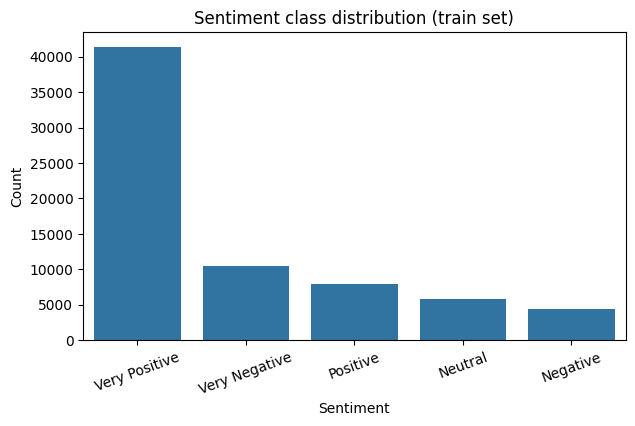

,proportion
sentiment,
Very Positive,59.131429
Very Negative,14.922857
Positive,11.405714
Neutral,8.217143
Negative,6.322857


In [ ]:
plt.figure(figsize=(7, 4))
order = train_df["sentiment"].value_counts().index
sns.countplot(data=train_df, x="sentiment", order=order)
plt.title("Sentiment class distribution (train set)")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

train_df["sentiment"].value_counts(normalize=True) * 100


### 7.2 Review length distribution per class

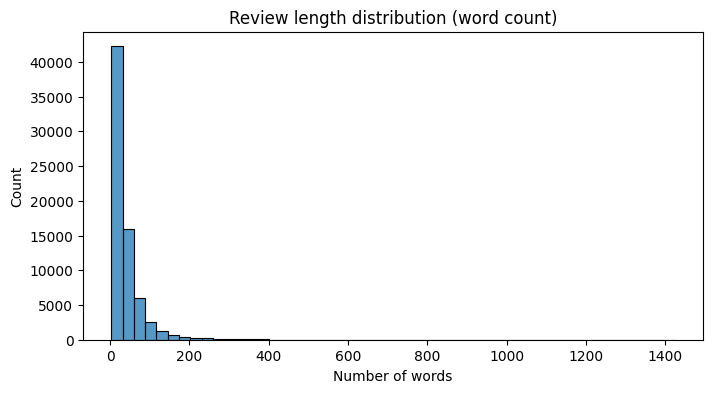

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,4426.0,41.946905,44.976741,3.0,16.0,30.0,52.0,598.0
Neutral,5752.0,43.259736,49.003316,3.0,15.0,30.0,52.0,721.0
Positive,7984.0,48.258016,57.792625,3.0,15.0,31.0,58.0,952.0
Very Negative,10446.0,34.773310,38.454839,3.0,13.0,25.0,43.0,1424.0
Very Positive,41392.0,35.453759,45.271347,3.0,11.0,22.0,43.0,1190.0


In [ ]:
train_df["review_len"] = train_df["review"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(data=train_df, x="review_len", bins=50)
plt.title("Review length distribution (word count)")
plt.xlabel("Number of words")
plt.show()

train_df.groupby("sentiment")["review_len"].describe()


### 7.3 Most frequent words per sentiment class

In [ ]:
from collections import Counter

stop_words = set(stopwords.words("english"))

def get_top_words(text_series, n=15):
    words = " ".join(text_series.astype(str)).lower().split()
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n)

for label in train_df["sentiment"].unique():
    subset = train_df[train_df["sentiment"] == label]["review"]
    print(f"--- Top words for: {label} ---")
    print(get_top_words(subset))
    print()


--- Top words for: Positive ---
[('good', 2500), ('like', 2388), ('hair', 2147), ('great', 2138), ('product', 1526), ('use', 1523), ('love', 1328), ('would', 1289), ('really', 1287), ('nice', 1270), ('little', 1241), ('one', 1169), ('stars', 1086), ('get', 1044), ('works', 998)]

--- Top words for: Very Positive ---
[('great', 14808), ('love', 14272), ('hair', 9909), ('good', 7301), ('product', 7238), ('use', 6622), ('like', 6544), ('really', 4804), ('easy', 4474), ('works', 4348), ('one', 4240), ('stars', 4043), ('five', 4013), ('skin', 3981), ('nice', 3778)]

--- Top words for: Negative ---
[('like', 1178), ('hair', 1168), ('product', 695), ('would', 684), ('use', 660), ('get', 647), ('one', 643), ('two', 613), ('good', 592), ('really', 520), ('work', 484), ('stars', 477), ('used', 403), ('even', 380), ('much', 361)]

--- Top words for: Neutral ---
[('like', 1624), ('hair', 1508), ('good', 1118), ('use', 954), ('product', 951), ('would', 895), ('get', 793), ('really', 781), ('one', 7

### 7.4 verified_purchase vs sentiment

In [ ]:
pd.crosstab(
    train_df["verified_purchase"], train_df["sentiment"], normalize="index"
) * 100


sentiment,Negative,Neutral,Positive,Very Negative,Very Positive
verified_purchase,,,,,
False,5.249699,7.415764,16.200361,11.823105,59.311071
True,6.435472,8.301238,10.902576,15.248137,59.112577


### 7.5 helpful_vote vs sentiment

In [ ]:
train_df.groupby("sentiment")["helpful_vote"].describe()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,4426.0,0.809083,4.099268,0.0,0.0,0.0,1.0,133.0
Neutral,5752.0,0.655598,2.320620,0.0,0.0,0.0,1.0,60.0
Positive,7984.0,0.984218,6.467642,0.0,0.0,0.0,1.0,431.0
Very Negative,10446.0,0.992246,4.740144,0.0,0.0,0.0,1.0,192.0
Very Positive,41392.0,0.959098,5.784568,0.0,0.0,0.0,1.0,467.0


### 7.7 Bigrams per sentiment class (visual)

Single words like "good" or "bad" don't capture negation or context
(e.g. "not good", "waste of money"). Bigrams give a clearer picture of what
actually drives each sentiment.


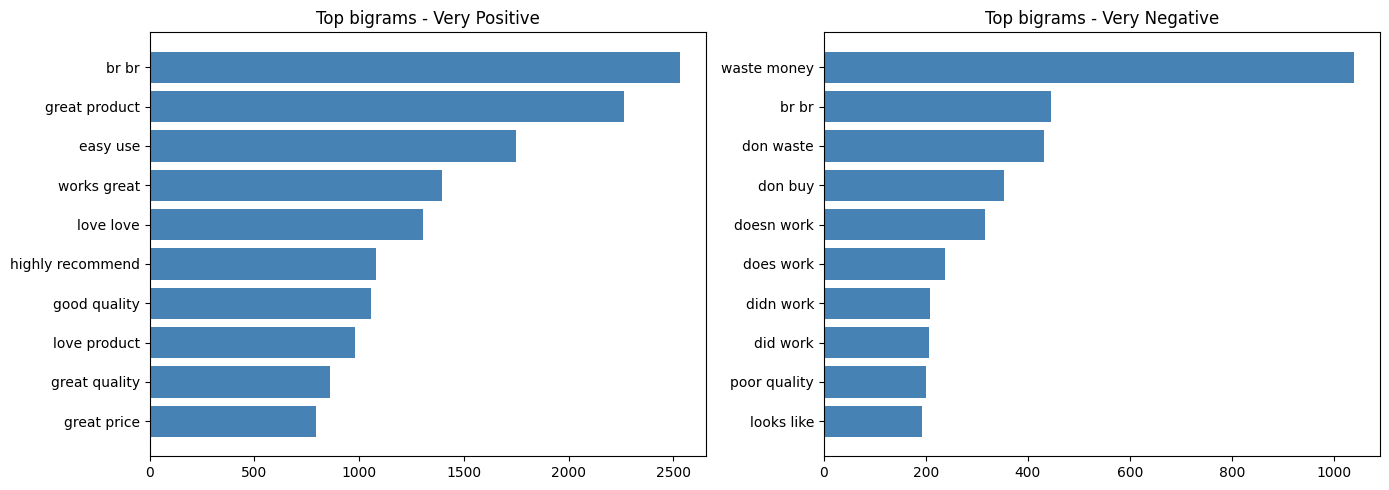

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

def plot_top_bigrams(df_subset, label, ax, n=10):
    cv = CountVectorizer(ngram_range=(2, 2), stop_words="english", max_features=n)
    bigram_matrix = cv.fit_transform(df_subset["review"].astype(str))
    counts = bigram_matrix.sum(axis=0).A1
    bigrams = cv.get_feature_names_out()
    order = np.argsort(counts)[::-1]
    ax.barh([bigrams[i] for i in order][::-1], [counts[i] for i in order][::-1], color="steelblue")
    ax.set_title(f"Top bigrams - {label}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_top_bigrams(train_df[train_df["sentiment"] == "Very Positive"], "Very Positive", axes[0])
plot_top_bigrams(train_df[train_df["sentiment"] == "Very Negative"], "Very Negative", axes[1])
plt.tight_layout()
plt.show()


### 7.8 main_category vs sentiment (visual)

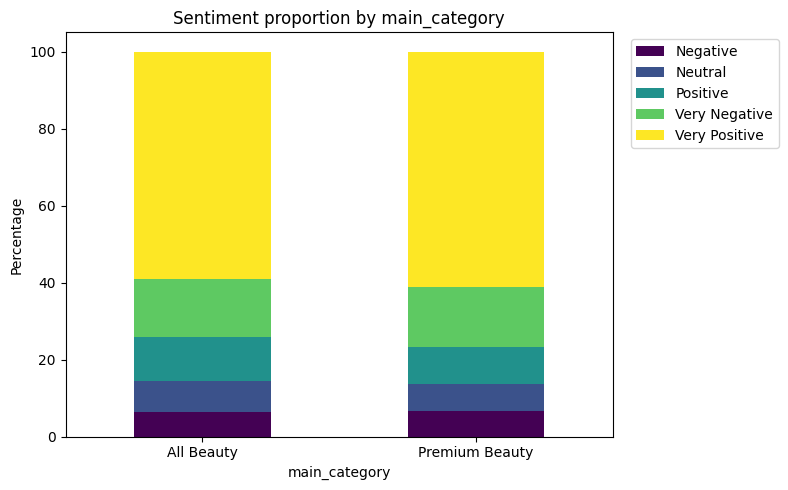

,count
main_category,
All Beauty,69222
Premium Beauty,778


In [ ]:
cross = pd.crosstab(train_df["main_category"], train_df["sentiment"], normalize="index") * 100

cross.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Sentiment proportion by main_category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

train_df["main_category"].value_counts()


### 7.9 Emoji presence check

Emojis can carry strong sentiment signal. We check how common they are before
deciding whether to strip them (classical ML) or keep them (transformer
pipeline, where they can still add signal).


In [ ]:
import re as _re

emoji_pattern = _re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U00002600-\U000026FF"
    "]+",
    flags=_re.UNICODE
)

train_df["has_emoji"] = train_df["review"].astype(str).apply(lambda t: bool(emoji_pattern.search(t)))
print("Reviews containing emoji:", train_df["has_emoji"].sum(), f"({train_df['has_emoji'].mean()*100:.2f}%)")

pd.crosstab(train_df["has_emoji"], train_df["sentiment"], normalize="index") * 100


Reviews containing emoji: 1835 (2.62%)


sentiment,Negative,Neutral,Positive,Very Negative,Very Positive
has_emoji,,,,,
False,6.396244,8.296046,11.473630,14.951955,58.882124
True,3.596730,5.286104,8.882834,13.841962,68.392371


### 7.10 Neutral vs neighboring classes - word overlap check

If Neutral shares most of its top words with Positive/Negative, the language
boundary between classes is weak, and merging into 3 classes
(Negative / Neutral / Positive) may give a stronger, more learnable model.


In [ ]:
neutral_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Neutral"]["review"], n=30))
positive_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Positive"]["review"], n=30))
negative_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Negative"]["review"], n=30))

print("Overlap Neutral/Positive:", neutral_words & positive_words)
print("Overlap Neutral/Negative:", neutral_words & negative_words)


Overlap Neutral/Positive: {'work', 'use', 'product', 'color', 'long', 'really', 'like', 'great', 'stars', 'much', 'pretty', 'nice', 'one', 'works', 'love', 'get', 'well', 'using', 'hair', 'would', 'good', 'still', 'used', 'little'}
Overlap Neutral/Negative: {'work', 'use', 'product', 'color', 'really', 'like', 'great', 'stars', 'much', 'one', 'brush', 'get', 'well', 'using', 'hair', 'would', 'good', 'small', 'used'}


## 8. Text preprocessing

Preprocessing is **not one-size-fits-all**. We build two separate cleaning
pipelines depending on which model family will consume the text:

- **Classical ML (TF-IDF + Logistic Regression / SVM / Naive Bayes)**:
  needs aggressive normalization - lowercasing, punctuation removal,
  stopword removal, lemmatization. These models only see word frequencies,
  so removing noise words and merging word forms helps a lot.

- **Transformer models (DistilBERT / BERT / RoBERTa)**:
  needs light cleaning only - keep punctuation, casing information and
  stopwords, since the model's own subword tokenizer and attention
  mechanism already handle context, negation and word forms. Aggressive
  cleaning here actually *hurts* performance.


### 8.1 Shared basic cleaning (applies to both pipelines)

In [ ]:
def basic_clean(text):
    """Light cleaning shared by every pipeline: remove links, HTML tags,
    and collapse extra whitespace. Keeps punctuation and casing intact."""
    text = re.sub(r"http\S+|www\S+", " ", text)   # URLs
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"\s+", " ", text).strip()         # extra whitespace
    return text

for split_df in [train_df, val_df, test_df]:
    split_df["review_basic"] = split_df["review"].apply(basic_clean)


### 8.2 Classical ML preprocessing (TF-IDF pipeline)

In [ ]:
lemmatizer = WordNetLemmatizer()

def clean_for_classical_ml(text):
    """Aggressive cleaning for TF-IDF based models:
    lowercase -> remove punctuation/numbers -> remove stopwords -> lemmatize."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)            # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

for split_df in [train_df, val_df, test_df]:
    split_df["review_clf_ml"] = split_df["review_basic"].apply(clean_for_classical_ml)

train_df[["review", "review_clf_ml"]].head(3)


,review,review_clf_ml
328723,Good Purchase Is a Christmas gift. Don't know...,good purchase christmas gift know well hold ye...
246525,Saved my mouth when I didn't yet have insuranc...,saved mouth yet insurance half tooth fell x x ...
606291,Great product Really makes a difference in my ...,great product really make difference hair alre...


### 8.3 Transformer preprocessing (DistilBERT / BERT / RoBERTa)

Only the shared basic cleaning (`review_basic`) is used here - no stopword
removal, no lemmatization, casing and punctuation are preserved. The model's
own tokenizer will handle subword splitting.


In [ ]:
# The transformer-ready text is simply the lightly cleaned version
for split_df in [train_df, val_df, test_df]:
    split_df["review_transformer"] = split_df["review_basic"]

train_df[["review", "review_transformer"]].head(3)


,review,review_transformer
328723,Good Purchase Is a Christmas gift. Don't know...,Good Purchase Is a Christmas gift. Don't know ...
246525,Saved my mouth when I didn't yet have insuranc...,Saved my mouth when I didn't yet have insuranc...
606291,Great product Really makes a difference in my ...,Great product Really makes a difference in my ...


Data Preparation, Class Weights & DataLoaders

In [ ]:
import torch
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# -------------------------------------------------------------------
# 0. Use the already-cleaned, already-split data (train_df/val_df/test_df).
#    The old code silently fell back to the raw `df` and raw `text` column,
#    throwing away all the dedup/cleaning/stratified-sampling work.
# -------------------------------------------------------------------
TEXT_COL = "review_transformer"   # lightly cleaned text built for transformer models

def map_to_3class(label):
    if label in ["Very Negative", "Negative"]:
        return "Negative"
    elif label == "Neutral":
        return "Neutral"
    else:
        return "Positive"

for split_df in [train_df, val_df, test_df]:
    split_df["sentiment_3class"] = split_df["sentiment"].apply(map_to_3class)

# -------------------------------------------------------------------
# 1. Label encoding - fit ONLY on train, reuse on val/test (avoids leakage)
# -------------------------------------------------------------------
le = LabelEncoder()
train_df["encoded_label"] = le.fit_transform(train_df["sentiment_3class"])
val_df["encoded_label"]   = le.transform(val_df["sentiment_3class"])
test_df["encoded_label"]  = le.transform(test_df["sentiment_3class"])
num_classes = len(le.classes_)

print(f"Classes ({num_classes}): {dict(zip(le.classes_, range(num_classes)))}")
print("\nTrain distribution:\n", train_df["sentiment_3class"].value_counts())

X_train, y_train = train_df[TEXT_COL].astype(str).values, train_df["encoded_label"].values
X_val, y_val     = val_df[TEXT_COL].astype(str).values,   val_df["encoded_label"].values
X_test, y_test   = test_df[TEXT_COL].astype(str).values,  test_df["encoded_label"].values

print(f"\nTrain: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

# -------------------------------------------------------------------
# 2. Class weights (computed on train only)
# -------------------------------------------------------------------
class_weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float)
print(f"\nClass weights: {class_weights_tensor}")

# -------------------------------------------------------------------
# 3. Tokenizer & Dataset - no fixed max_length padding here; a collator pads
#    dynamically per batch instead, which is faster and buys you extra epochs
#    in the same time budget. Check train_df["review_len"] (cell 31) - beauty
#    reviews are short, so 128 tokens is plenty for the vast majority.
# -------------------------------------------------------------------
MODEL_NAME = "microsoft/deberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 128

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_len = tokenizer, max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(str(self.texts[idx]), truncation=True, max_length=self.max_len)
        enc = {k: torch.tensor(v) for k, v in enc.items()}
        enc["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return enc

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

BATCH_SIZE = 16
train_dataset = SentimentDataset(X_train, y_train, tokenizer)
val_dataset   = SentimentDataset(X_val, y_val, tokenizer)
test_dataset  = SentimentDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)

sample_batch = next(iter(train_loader))
print("\ninput_ids shape:", sample_batch["input_ids"].shape)

Classes (3): {'Negative': 0, 'Neutral': 1, 'Positive': 2}

Train distribution:
 sentiment_3class
Positive    49376
Negative    14872
Neutral      5752
Name: count, dtype: int64

Train: 70,000 | Val: 15,000 | Test: 15,000

Class weights: tensor([1.5689, 4.0566, 0.4726])


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            


input_ids shape: torch.Size([16, 128])


Model Setup, Fine-Tuning, Validation & Model Checkpointing

In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, get_cosine_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")
if device.type == "cpu":
    print("⚠️ Training DeBERTa-v3 on CPU is impractical for 70k rows.")
    print("👉 Runtime -> Change runtime type -> T4 GPU, then re-run from here.")

MODEL_NAME = "microsoft/deberta-v3-base"
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes)
model = model.to(device=device, dtype=torch.float32)
weights = class_weights_tensor.to(device=device, dtype=torch.float32)

# label_smoothing lowered 0.1 -> 0.05: stacked with class weights, 0.1 over-flattened
# the signal for the minority Neutral class
criterion = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)

EPOCHS = 5           # was 3; early stopping (patience=2) still cuts it short if needed
LEARNING_RATE = 1.5e-5

no_decay = ["bias", "LayerNorm.weight"]
optimizer_grouped_parameters = [
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
     "weight_decay": 0.01},   # was 0.05 - too aggressive for a short fine-tune, risked underfitting
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0},
]
optimizer = AdamW(optimizer_grouped_parameters, lr=LEARNING_RATE)

total_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * 0.10), num_training_steps=total_steps
)

use_cuda = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

best_val_loss = float("inf")
patience, patience_counter = 2, 0
BEST_MODEL_PATH = "best_deberta_3class_model.pt"

print("\nStarting DeBERTa-v3 fine-tuning (3-class)...")

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        optimizer.zero_grad()
        batch = {k: v.to(device) for k, v in batch.items()}
        if use_cuda:
            with torch.amp.autocast("cuda"):
                outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                loss = criterion(outputs.logits, batch["labels"])
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
            loss = criterion(outputs.logits, batch["labels"])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        scheduler.step()
        train_loss += loss.item()
    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            batch = {k: v.to(device) for k, v in batch.items()}
            if use_cuda:
                with torch.amp.autocast("cuda"):
                    outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                    loss = criterion(outputs.logits, batch["labels"])
            else:
                outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                loss = criterion(outputs.logits, batch["labels"])
            val_loss += loss.item()
            preds = torch.argmax(outputs.logits, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(batch["labels"].cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average="macro")

    print(f"\n--- Epoch {epoch+1} ---")
    print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1 (macro): {val_f1:.4f}")

    if avg_val_loss < best_val_loss:
        print(f"Val loss improved ({best_val_loss:.4f} -> {avg_val_loss:.4f}). Saving checkpoint.")
        best_val_loss = avg_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
    else:
        patience_counter += 1
        print(f"No improvement for {patience_counter} epoch(s).")
        if patience_counter >= patience:
            print("Early stopping.")
            break

Using compute device: cuda


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier


Starting DeBERTa-v3 fine-tuning (3-class)...


... (7 outputs left out)


--- Epoch 2 ---
Train Loss: 0.6348 | Val Loss: 0.6883 | Val Acc: 0.9136 | Val F1 (macro): 0.7916
No improvement for 1 epoch(s).


Epoch 3/5 [Train]:   0%|          | 0/4375 [00:00<?, ?it/s]

Epoch 3/5 [Val]:   0%|          | 0/938 [00:00<?, ?it/s]


--- Epoch 3 ---
Train Loss: 0.5835 | Val Loss: 0.7043 | Val Acc: 0.9074 | Val F1 (macro): 0.7960
No improvement for 2 epoch(s).
Early stopping.


Test Set Evaluation, Full Classification Report, and Confusion Matrix Visualization!

Test evaluation:   0%|          | 0/938 [00:00<?, ?it/s]

Test Accuracy   : 0.9005
Test F1 (macro) : 0.7904

              precision    recall  f1-score   support

    Negative       0.86      0.91      0.88      3187
     Neutral       0.46      0.61      0.53      1232
    Positive       0.98      0.93      0.96     10581

    accuracy                           0.90     15000
   macro avg       0.77      0.82      0.79     15000
weighted avg       0.92      0.90      0.91     15000



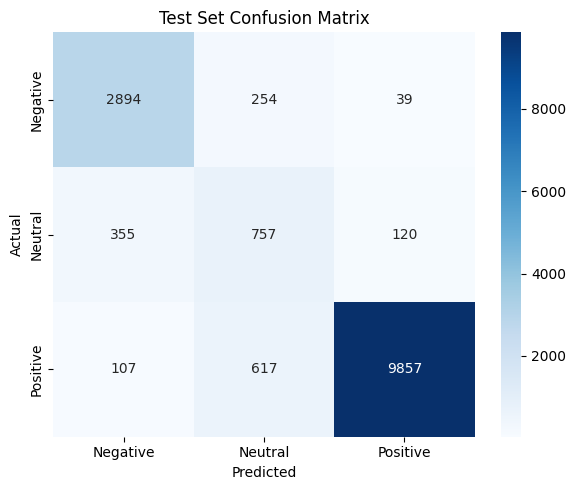

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Reload the BEST checkpoint (lowest val loss) - previously this cell was empty,
# so no test accuracy existed and, if run naively, would've evaluated whatever
# the last training epoch left in memory rather than the best one.
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.to(device)
model.eval()

test_preds, test_labels = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Test evaluation"):
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
        preds = torch.argmax(outputs.logits, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(batch["labels"].cpu().numpy())

test_acc = accuracy_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds, average="macro")
print(f"Test Accuracy   : {test_acc:.4f}")
print(f"Test F1 (macro) : {test_f1:.4f}\n")

print(classification_report(test_labels, test_preds, target_names=le.classes_))

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

Threshold tuning on your existing best_model (no retraining)

In [ ]:
# Title: Post-hoc threshold/bias tuning (matches this notebook's structure)
# Purpose: Reload the saved DeBERTa checkpoint, get val/test probabilities,
# then find a per-class bias vector on val (maximizing macro F1) and apply it to test.
import numpy as np
import torch
from sklearn.metrics import f1_score, classification_report

# --- Rebuild model architecture and reload the saved BEST checkpoint ---
# (num_classes, MODEL_NAME, le, val_loader, test_loader should already exist
#  from cells 55/57; if this is a fresh session, rerun cells 55 and the
#  DataLoader-building part of 55 first so val_loader/test_loader exist)
from transformers import AutoModelForSequenceClassification

BEST_MODEL_PATH = "best_deberta_3class_model.pt"  # must match what cell 57 saved

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.to(device)
model.eval()

def get_probs_and_labels(loader):
    """Run the model over a loader and return softmax probabilities + true labels."""
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
            probs = torch.softmax(outputs.logits, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(batch["labels"].cpu().numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)

# --- Get val probabilities to tune the bias ---
val_probs, val_labels = get_probs_and_labels(val_loader)

# --- Grid search a bias for Negative (idx 0) and Neutral (idx 1); Positive anchored at 0 ---
grid = np.arange(-0.30, 0.31, 0.02)
best_bias, best_f1 = None, -1.0

for b_neg in grid:
    for b_neu in grid:
        bias = np.array([b_neg, b_neu, 0.0])
        preds = (val_probs + bias).argmax(axis=1)
        f1 = f1_score(val_labels, preds, average="macro")
        if f1 > best_f1:
            best_f1, best_bias = f1, bias

print(f"Best val macro-F1: {best_f1:.4f} with bias {best_bias}")

# --- Apply the tuned bias to the test set ---
test_probs, test_labels = get_probs_and_labels(test_loader)
test_preds_adj = (test_probs + best_bias).argmax(axis=1)

print("\n--- Test set with tuned bias ---")
print(classification_report(
    test_labels, test_preds_adj,
    target_names=le.classes_, digits=4, zero_division=0,
))

print("\n--- Test set without bias (for comparison) ---")
print(classification_report(
    test_labels, test_probs.argmax(axis=1),
    target_names=le.classes_, digits=4, zero_division=0,
))

Best val macro-F1: 0.7897 with bias [-0.3  -0.16  0.  ]

--- Test set with tuned bias ---
              precision    recall  f1-score   support

    Negative     0.8727    0.8952    0.8838      3187
     Neutral     0.4828    0.6274    0.5457      1232
    Positive     0.9809    0.9391    0.9596     10581

    accuracy                         0.9042     15000
   macro avg     0.7788    0.8206    0.7964     15000
weighted avg     0.9170    0.9042    0.9095     15000


--- Test set without bias (for comparison) ---
              precision    recall  f1-score   support

    Negative     0.8623    0.9081    0.8846      3187
     Neutral     0.4650    0.6144    0.5294      1232
    Positive     0.9841    0.9316    0.9571     10581

    accuracy                         0.9005     15000
   macro avg     0.7705    0.8180    0.7904     15000
weighted avg     0.9156    0.9005    0.9066     15000



Data prep (now unweighted, since weighting hurt overall performance)

In [ ]:
import torch
import numpy as np
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

TEXT_COL = "review_transformer"

def map_to_3class(label):
    if label in ["Very Negative", "Negative"]:
        return "Negative"
    elif label == "Neutral":
        return "Neutral"
    else:
        return "Positive"

for split_df in [train_df, val_df, test_df]:
    split_df["sentiment_3class"] = split_df["sentiment"].apply(map_to_3class)

# Label encoding - fit ONLY on train, reuse on val/test
le = LabelEncoder()
train_df["encoded_label"] = le.fit_transform(train_df["sentiment_3class"])
val_df["encoded_label"]   = le.transform(val_df["sentiment_3class"])
test_df["encoded_label"]  = le.transform(test_df["sentiment_3class"])
num_classes = len(le.classes_)

print(f"Classes ({num_classes}): {dict(zip(le.classes_, range(num_classes)))}")
print("\nTrain distribution:\n", train_df["sentiment_3class"].value_counts())

X_train, y_train = train_df[TEXT_COL].astype(str).values, train_df["encoded_label"].values
X_val, y_val     = val_df[TEXT_COL].astype(str).values,   val_df["encoded_label"].values
X_test, y_test   = test_df[TEXT_COL].astype(str).values,  test_df["encoded_label"].values

print(f"\nTrain: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

# NOTE: class_weights removed - the unweighted run beat the weighted run on
# accuracy, macro F1, AND Positive/Negative F1, with Neutral F1 essentially
# tied. Post-hoc bias tuning (added in the test-eval cell below) recovers
# most of what weighting was trying to buy, without the accuracy cost.

MODEL_NAME = "microsoft/deberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 128

class SentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_len = tokenizer, max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(str(self.texts[idx]), truncation=True, max_length=self.max_len)
        enc = {k: torch.tensor(v) for k, v in enc.items()}
        enc["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return enc

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

BATCH_SIZE = 16
train_dataset = SentimentDataset(X_train, y_train, tokenizer)
val_dataset   = SentimentDataset(X_val, y_val, tokenizer)
test_dataset  = SentimentDataset(X_test, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)

sample_batch = next(iter(train_loader))
print("\ninput_ids shape:", sample_batch["input_ids"].shape)

Classes (3): {'Negative': 0, 'Neutral': 1, 'Positive': 2}

Train distribution:
 sentiment_3class
Positive    49376
Negative    14872
Neutral      5752
Name: count, dtype: int64

Train: 70,000 | Val: 15,000 | Test: 15,000

input_ids shape: torch.Size([16, 128])


Training loop (unweighted CrossEntropyLoss)

In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, get_cosine_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")
if device.type == "cpu":
    print("⚠️ Training DeBERTa-v3 on CPU is impractical for 70k rows.")
    print("👉 Runtime -> Change runtime type -> T4 GPU, then re-run from here.")

MODEL_NAME = "microsoft/deberta-v3-base"
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes)
model = model.to(device=device, dtype=torch.float32)

# Unweighted loss - the class-weighted version over-corrected and hurt
# Positive/overall accuracy more than it helped Neutral (see comparison notebook)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

EPOCHS = 5
LEARNING_RATE = 1.5e-5

no_decay = ["bias", "LayerNorm.weight"]
optimizer_grouped_parameters = [
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
     "weight_decay": 0.01},
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
     "weight_decay": 0.0},
]
optimizer = AdamW(optimizer_grouped_parameters, lr=LEARNING_RATE)

total_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * 0.10), num_training_steps=total_steps
)

use_cuda = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

best_val_loss = float("inf")
patience, patience_counter = 2, 0
BEST_MODEL_PATH = "best_deberta_3class_model.pt"

print("\nStarting DeBERTa-v3 fine-tuning (3-class, unweighted)...")

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        optimizer.zero_grad()
        batch = {k: v.to(device) for k, v in batch.items()}
        if use_cuda:
            with torch.amp.autocast("cuda"):
                outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                loss = criterion(outputs.logits, batch["labels"])
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
            loss = criterion(outputs.logits, batch["labels"])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        scheduler.step()
        train_loss += loss.item()
    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    val_loss = 0.0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Val]"):
            batch = {k: v.to(device) for k, v in batch.items()}
            if use_cuda:
                with torch.amp.autocast("cuda"):
                    outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                    loss = criterion(outputs.logits, batch["labels"])
            else:
                outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
                loss = criterion(outputs.logits, batch["labels"])
            val_loss += loss.item()
            preds = torch.argmax(outputs.logits, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(batch["labels"].cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average="macro")

    print(f"\n--- Epoch {epoch+1} ---")
    print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1 (macro): {val_f1:.4f}")

    if avg_val_loss < best_val_loss:
        print(f"Val loss improved ({best_val_loss:.4f} -> {avg_val_loss:.4f}). Saving checkpoint.")
        best_val_loss = avg_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
    else:
        patience_counter += 1
        print(f"No improvement for {patience_counter} epoch(s).")
        if patience_counter >= patience:
            print("Early stopping.")
            break

Using compute device: cuda


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier


Starting DeBERTa-v3 fine-tuning (3-class, unweighted)...


Epoch 1/5 [Train]:   0%|          | 0/4375 [00:00<?, ?it/s]

Epoch 1/5 [Val]:   0%|          | 0/938 [00:00<?, ?it/s]

... (3 outputs left out)


--- Epoch 2 ---
Train Loss: 0.3406 | Val Loss: 0.3697 | Val Acc: 0.9124 | Val F1 (macro): 0.7604
No improvement for 1 epoch(s).


Epoch 3/5 [Train]:   0%|          | 0/4375 [00:00<?, ?it/s]

Epoch 3/5 [Val]:   0%|          | 0/938 [00:00<?, ?it/s]


--- Epoch 3 ---
Train Loss: 0.3061 | Val Loss: 0.3673 | Val Acc: 0.9151 | Val F1 (macro): 0.7957
No improvement for 2 epoch(s).
Early stopping.


Test evaluation with bias tuning built in

Scoring:   0%|          | 0/938 [00:00<?, ?it/s]


=== Baseline (no bias) ===
Test Accuracy   : 0.9154
Test F1 (macro) : 0.7746

              precision    recall  f1-score   support

    Negative       0.82      0.95      0.88      3187
     Neutral       0.62      0.38      0.48      1232
    Positive       0.97      0.97      0.97     10581

    accuracy                           0.92     15000
   macro avg       0.80      0.77      0.77     15000
weighted avg       0.91      0.92      0.91     15000



Scoring:   0%|          | 0/938 [00:00<?, ?it/s]


Best val macro-F1 with bias: 0.7988, bias=[-0.3   0.26  0.  ]

=== With tuned bias ===
Test Accuracy   : 0.9141
Test F1 (macro) : 0.8021

              precision    recall  f1-score   support

    Negative       0.87      0.89      0.88      3187
     Neutral       0.53      0.58      0.56      1232
    Positive       0.98      0.96      0.97     10581

    accuracy                           0.91     15000
   macro avg       0.79      0.81      0.80     15000
weighted avg       0.92      0.91      0.92     15000



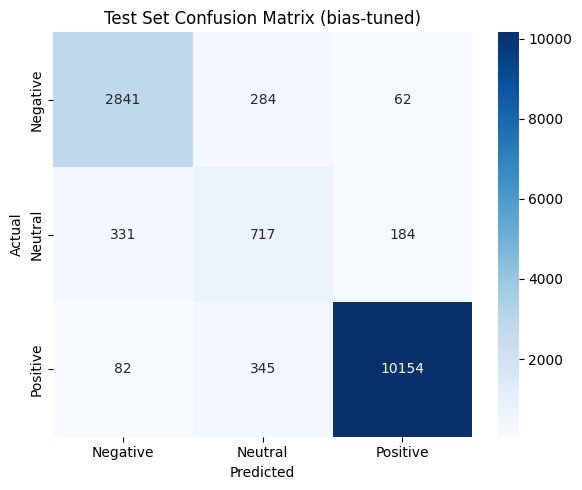

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Reload the BEST checkpoint (lowest val loss)
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.to(device)
model.eval()

def get_probs_and_labels(loader):
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch in tqdm(loader, desc="Scoring"):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
            probs = torch.softmax(outputs.logits, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(batch["labels"].cpu().numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)

# --- Baseline (no bias) ---
test_probs, test_labels = get_probs_and_labels(test_loader)
test_preds = test_probs.argmax(axis=1)
test_acc = accuracy_score(test_labels, test_preds)
test_f1 = f1_score(test_labels, test_preds, average="macro")
print(f"\n=== Baseline (no bias) ===")
print(f"Test Accuracy   : {test_acc:.4f}")
print(f"Test F1 (macro) : {test_f1:.4f}\n")
print(classification_report(test_labels, test_preds, target_names=le.classes_))

# --- Bias tuning on val, applied to test ---
val_probs, val_labels = get_probs_and_labels(val_loader)
grid = np.arange(-0.30, 0.31, 0.02)
best_bias, best_f1 = None, -1.0
for b_neg in grid:
    for b_neu in grid:
        bias = np.array([b_neg, b_neu, 0.0])
        preds = (val_probs + bias).argmax(axis=1)
        f1 = f1_score(val_labels, preds, average="macro")
        if f1 > best_f1:
            best_f1, best_bias = f1, bias
print(f"\nBest val macro-F1 with bias: {best_f1:.4f}, bias={best_bias}")

test_preds_adj = (test_probs + best_bias).argmax(axis=1)
test_acc_adj = accuracy_score(test_labels, test_preds_adj)
test_f1_adj = f1_score(test_labels, test_preds_adj, average="macro")
print(f"\n=== With tuned bias ===")
print(f"Test Accuracy   : {test_acc_adj:.4f}")
print(f"Test F1 (macro) : {test_f1_adj:.4f}\n")
print(classification_report(test_labels, test_preds_adj, target_names=le.classes_))

cm = confusion_matrix(test_labels, test_preds_adj)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Set Confusion Matrix (bias-tuned)")
plt.tight_layout()
plt.show()

In [ ]:
neutral_idx = list(le.classes_).index("Neutral")
wrong_neutral_mask = (test_labels == neutral_idx) & (test_preds_adj != neutral_idx)
wrong_samples = test_df.iloc[np.where(wrong_neutral_mask)[0]]
wrong_samples[["review", "sentiment"]].sample(15, random_state=42)

,review,sentiment
356318,Not the same as pictured Hard to maintain and ...,Neutral
84160,Urban Twist Product needs additional length or...,Neutral
16093,Not great... I really wish I didn't fall for e...,Neutral
546622,Perfect It is beautiful and arrived on time! P...,Neutral
210622,Not worth the money I thought it was going to ...,Neutral
298532,Easy to use Easy to use makes it easy to even ...,Neutral
379969,"Mis-purposed Frankly, these seem more intended...",Neutral
264607,Not that great These are getting stringy…. Fal...,Neutral
100577,this is my fault for not paying attention to t...,Neutral
51223,dislike scent This soap did a nice job of clea...,Neutral


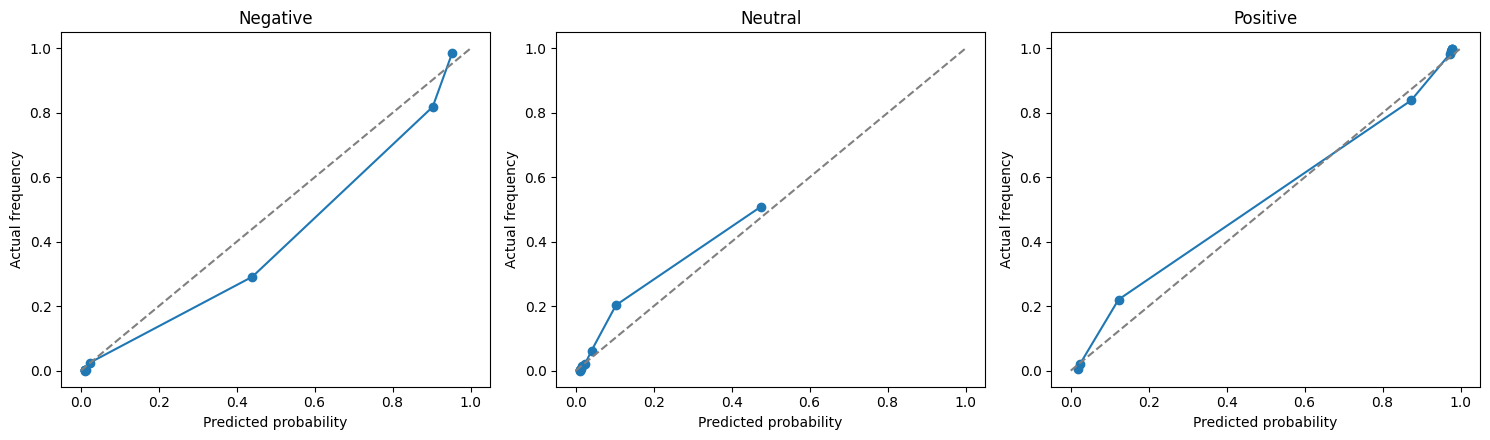

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, idx, name in zip(axes, range(3), le.classes_):
    y_true_bin = (test_labels == idx).astype(int)
    y_prob = test_probs[:, idx]
    prob_true, prob_pred = calibration_curve(y_true_bin, y_prob, n_bins=10, strategy="quantile")
    ax.plot(prob_pred, prob_true, marker="o", label=name)
    ax.plot([0,1],[0,1], linestyle="--", color="gray")
    ax.set_title(name)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Actual frequency")
plt.tight_layout()
plt.show()

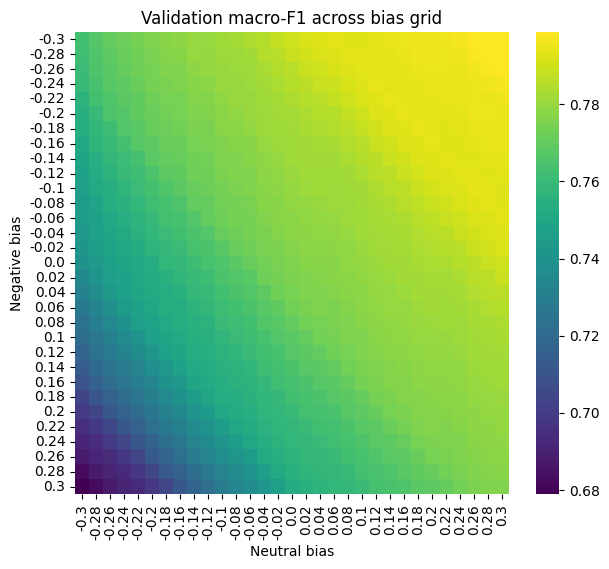

In [ ]:
# نفس الـ grid والمتغيرات اللي عندك في Cell 61 (grid, val_probs, val_labels)
# التعديل الوحيد: نخزّن macro-F1 لكل نقطة في مصفوفة بدل ما ناخد بس الأفضل

f1_grid = np.zeros((len(grid), len(grid)))  # صفوف = Negative bias, أعمدة = Neutral bias

for i, b_neg in enumerate(grid):
    for j, b_neu in enumerate(grid):
        bias = np.array([b_neg, b_neu, 0.0])
        preds = (val_probs + bias).argmax(axis=1)
        f1_grid[i, j] = f1_score(val_labels, preds, average="macro")

# دلوقتي f1_grid موجودة وجاهزة للـ heatmap
plt.figure(figsize=(7,6))
sns.heatmap(f1_grid, xticklabels=grid.round(2), yticklabels=grid.round(2), cmap="viridis")
plt.xlabel("Neutral bias")
plt.ylabel("Negative bias")
plt.title("Validation macro-F1 across bias grid")
plt.show()

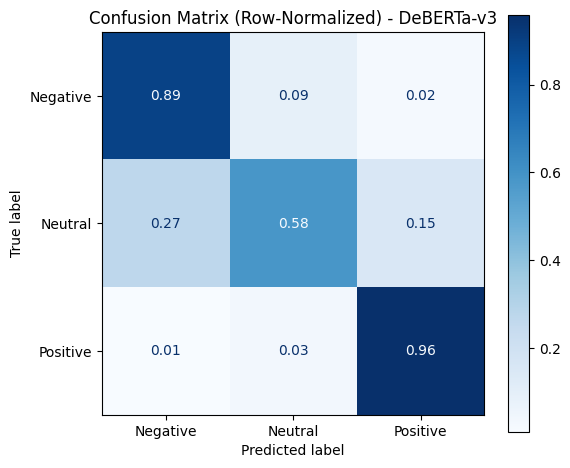

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(
    test_labels, test_preds_adj, display_labels=le.classes_,
    normalize="true", cmap="Blues", ax=ax, values_format=".2f"
)
plt.title("Confusion Matrix (Row-Normalized) - DeBERTa-v3")
plt.tight_layout()
plt.show()

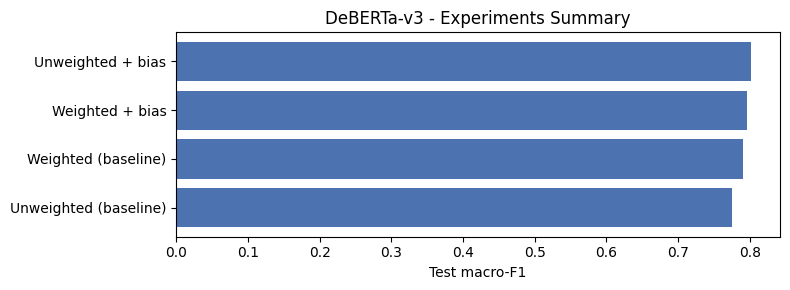

In [ ]:
import pandas as pd
results = pd.DataFrame([
    {"setting": "Weighted (baseline)", "macro_f1": 0.7904},
    {"setting": "Weighted + bias", "macro_f1": 0.7964},
    {"setting": "Unweighted (baseline)", "macro_f1": 0.7746},
    {"setting": "Unweighted + bias", "macro_f1": 0.8021},
])
plt.figure(figsize=(8,3))
order = results.sort_values("macro_f1")
plt.barh(order["setting"], order["macro_f1"], color="#4C72B0")
plt.xlabel("Test macro-F1")
plt.title("DeBERTa-v3 - Experiments Summary")
plt.tight_layout()
plt.show()